# Lab 4: Simple and Multiple Linear Regression

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Objective
Implement simple and multiple linear regression, predict continuous values, and analyze regression coefficients.

## Dataset: Kaggle Medical Cost Personal Dataset


## 1. Import libraries


In [7]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## 2. Load and inspect the Kaggle dataset


In [8]:
csv_candidates = [
    Path("/kaggle/input/insurance/insurance.csv"),
    Path("insurance.csv"),
    Path("data/insurance.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find insurance.csv. Download it from the Kaggle dataset page and "
        "place it beside this notebook (or in ./data/insurance.csv). On Kaggle, attach "
        "the dataset so it is available under /kaggle/input/insurance/."
    )

df = pd.read_csv(csv_path)
print("Loaded file:", csv_path)
print("Dataset shape (rows, columns):", df.shape)
df.head()

Loaded file: insurance.csv
Dataset shape (rows, columns): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [9]:
# Check column types, missing values, and summary statistics
print("Column data types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nSummary statistics:")
df.describe(include="all")

Column data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Summary statistics:


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


## 3. Prepare features and target

The target `charges` is a continuous number. For simple regression, BMI will be the only input feature. For multiple regression, we will use all six input attributes. The categorical columns are converted into indicator columns using one-hot encoding.

In [10]:
target = df["charges"]

# Simple linear regression uses one numerical feature
X_simple = df[["bmi"]]

# Multiple regression uses all six input attributes
X_multiple = pd.get_dummies(
    df.drop(columns="charges"),
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

print("Simple regression feature:", list(X_simple.columns))
print("Number of multiple regression features:", X_multiple.shape[1])
print("Example encoded features:")
X_multiple.head()

Simple regression feature: ['bmi']
Number of multiple regression features: 8
Example encoded features:


,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


## 4. Split data into training and testing sets

We keep 20% of the records aside for testing. The same split is used for both models so their test results can be compared fairly.

In [11]:
X_train_simple, X_test_simple, y_train, y_test = train_test_split(
    X_simple, target, test_size=0.20, random_state=42
)

X_train_multiple, X_test_multiple, _, _ = train_test_split(
    X_multiple, target, test_size=0.20, random_state=42
)

print("Training records:", len(X_train_simple))
print("Testing records:", len(X_test_simple))

Training records: 1070
Testing records: 268


## 5. Simple linear regression

Simple linear regression uses one input feature to estimate a continuous target. Here the equation is `charges = intercept + coefficient × BMI`.

In [12]:
simple_model = LinearRegression()
simple_model.fit(X_train_simple, y_train)
simple_predictions = simple_model.predict(X_test_simple)

print(f"Intercept: {simple_model.intercept_:.2f}")
print(f"BMI coefficient: {simple_model.coef_[0]:.2f}")

Intercept: 1353.07
BMI coefficient: 392.44


### Interpret the simple regression coefficient

The BMI coefficient estimates the change in predicted charges (in dollars) for a one-unit increase in BMI in this one-feature model. This is an association in the sample; it does not establish that BMI alone causes a change in medical charges.

In [13]:
simple_results = pd.DataFrame({
    "Actual charges": y_test.values,
    "Predicted charges": simple_predictions
})
simple_results.head(10)

,Actual charges,Predicted charges
0,9095.06825,11232.663072
1,5272.17580,13134.018128
2,29330.98315,11903.729562
3,9301.89355,11456.351902
4,33750.29180,13879.647562
5,4536.25900,18188.600817
6,2117.33885,10188.781864
7,14210.53595,16228.380279
8,3732.62510,8138.300921
9,10264.44210,12612.077524


## 6. Multiple linear regression

Multiple regression uses several input features at once. The equation has an intercept and one coefficient for every encoded feature. Each coefficient estimates a change in predicted charges while the other included features are held constant.

In [14]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_multiple, y_train)
multiple_predictions = multiple_model.predict(X_test_multiple)

coefficient_table = pd.DataFrame({
    "Feature": X_multiple.columns,
    "Coefficient": multiple_model.coef_
})
print(f"Intercept: {multiple_model.intercept_:.2f}")
coefficient_table.sort_values("Coefficient", ascending=False).round(2)

Intercept: -11931.22


,Feature,Coefficient
4,smoker_yes,23651.13
2,children,425.28
1,bmi,337.09
0,age,256.98
3,sex_male,-18.59
5,region_northwest,-370.68
6,region_southeast,-657.86
7,region_southwest,-809.80


### Interpret the multiple regression coefficients

`age`, `bmi`, and `children` coefficients are measured in dollars per one-unit increase in those features, holding the other included features constant. For binary indicator columns, the coefficient is the estimated difference from the omitted reference category. For example, `smoker_yes` is compared with non-smokers. `drop_first=True` omits one category from each group to avoid redundant columns. Coefficients reflect patterns in this dataset and do not prove causation.

In [15]:
multiple_results = X_test_multiple.copy()
multiple_results["Actual charges"] = y_test.values
multiple_results["Predicted charges"] = multiple_predictions
multiple_results[["age", "bmi", "children", "Actual charges", "Predicted charges"]].head(10).round(2)

,age,bmi,children,Actual charges,Predicted charges
764,45,25.18,2,9095.07,8969.55
887,36,30.02,0,5272.18,7068.75
890,64,26.88,0,29330.98,36858.41
1293,46,25.74,3,9301.89,9454.68
259,19,31.92,0,33750.29,26973.17
1312,34,42.90,1,4536.26,10864.11
899,19,22.52,0,2117.34,170.28
752,64,37.90,0,14210.54,16903.45
1286,28,17.29,0,3732.63,1092.43
707,49,28.69,3,10264.44,11218.34


## 7. Evaluate both models

Mean absolute error (MAE) and root mean squared error (RMSE) report typical prediction error in dollars; smaller values are better. R-squared (R²) describes how much target variation the model explains on this test set; values closer to 1 indicate a better fit.

In [16]:
def regression_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE ($)": mean_absolute_error(actual, predicted),
        "RMSE ($)": mse ** 0.5,
        "R-squared": r2_score(actual, predicted)
    }

comparison = pd.DataFrame({
    "Simple (BMI only)": regression_metrics(y_test, simple_predictions),
    "Multiple (all attributes)": regression_metrics(y_test, multiple_predictions)
}).T
comparison.round(2)

,MAE ($),RMSE ($),R-squared
Simple (BMI only),9784.65,12210.04,0.04
Multiple (all attributes),4181.19,5796.28,0.78


## 8. Visualize the simple regression

The scatter plot shows the test records and their charges. The red line shows predictions from the one-feature model across the BMI range.

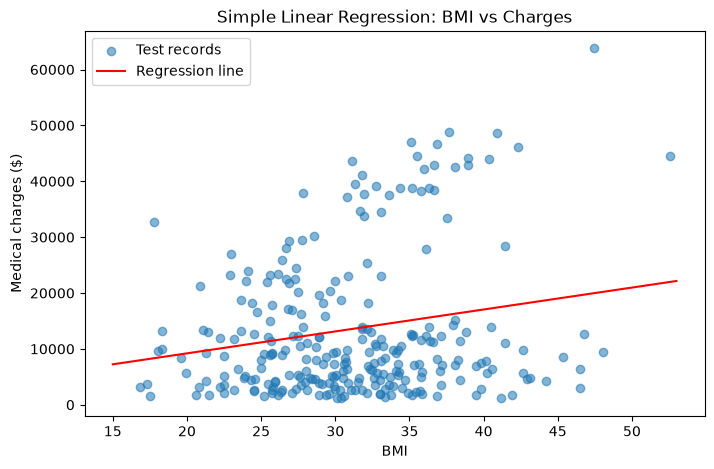

In [17]:
bmi_range = pd.DataFrame({
    "bmi": pd.Series(range(int(df["bmi"].min()), int(df["bmi"].max()) + 1))
})

plt.figure(figsize=(8, 5))
plt.scatter(X_test_simple["bmi"], y_test, alpha=0.55, label="Test records")
plt.plot(bmi_range["bmi"], simple_model.predict(bmi_range), color="red", label="Regression line")
plt.xlabel("BMI")
plt.ylabel("Medical charges ($)")
plt.title("Simple Linear Regression: BMI vs Charges")
plt.legend()
plt.show()

## 9. Visualize multiple regression predictions



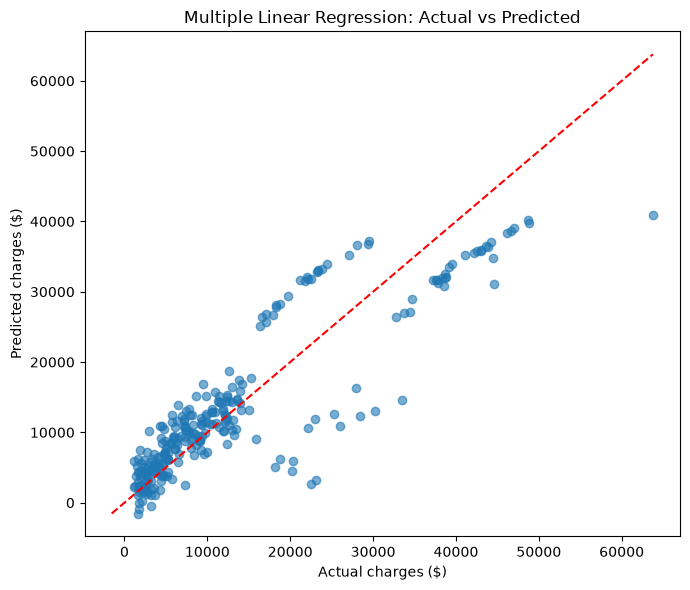

In [18]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, multiple_predictions, alpha=0.6)
line_min = min(y_test.min(), multiple_predictions.min())
line_max = max(y_test.max(), multiple_predictions.max())
plt.plot([line_min, line_max], [line_min, line_max], color="red", linestyle="--")
plt.xlabel("Actual charges ($)")
plt.ylabel("Predicted charges ($)")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.tight_layout()
plt.show()

## 10. Predict for a new example


In [19]:
new_person = pd.DataFrame({
    "age": [30],
    "sex": ["female"],
    "bmi": [25.0],
    "children": [1],
    "smoker": ["no"],
    "region": ["southeast"]
})

new_person_encoded = pd.get_dummies(
    new_person, columns=["sex", "smoker", "region"],
    drop_first=True, dtype=int
).reindex(columns=X_multiple.columns, fill_value=0)
predicted_charge = multiple_model.predict(new_person_encoded)[0]
print(f"Estimated charges: ${predicted_charge:,.2f}")

Estimated charges: $4,630.64
